<a href="https://colab.research.google.com/github/Prachisagat2/Myward/blob/main/train_civic_yolo_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# My Ward - Train the civic issue detector (YOLOv8)

Trains a model that spots potholes, garbage, streetlights etc. in a photo. The result is one file, `best.pt`,
which you put in your project's `models/` folder.

**Before you start**
1. Menu **Runtime > Change runtime type > T4 GPU > Save** (training on CPU is far too slow).
2. Have a dataset ready in **YOLO format** as a `.zip` (see step 3). Roboflow Universe and Kaggle have
   pothole / garbage datasets. Check each dataset's licence before using it.
3. Run the cells top to bottom.

## 1. Install

In [ ]:
!pip -q install ultralytics

## 2. Check the GPU

In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    print("No GPU! Use Runtime > Change runtime type > T4 GPU, then run again.")

GPU available: True
Tesla T4


## 3. Load your dataset

**Option A - upload a zip** (run this cell and pick your `.zip`). The zip must contain `data.yaml` plus
`train/`, `valid/` (and optionally `test/`) folders, each with `images/` and `labels/`.

In [ ]:
from google.colab import files
import zipfile, os

os.makedirs("/content/datasets/civic", exist_ok=True)
uploaded = files.upload()
for name in uploaded:
    with zipfile.ZipFile(name) as z:
        z.extractall("/content/datasets/civic")
print("Extracted.")

Saving Pothole Detection.v1i.yolov8.zip to Pothole Detection.v1i.yolov8 (1).zip
Extracted.


**Option B - download from Roboflow** (skip Option A). On the dataset page choose *Download Dataset > YOLOv8 >
show download code*, and paste your own values below. Never share your API key publicly.

In [ ]:
# Uncomment and fill in to use Roboflow instead of Option A
# !pip -q install roboflow
# from roboflow import Roboflow
# rf = Roboflow(api_key="YOUR_API_KEY")
# project = rf.workspace("WORKSPACE").project("PROJECT")
# project.version(1).download("yolov8", location="/content/datasets/civic")

## 4. Fix `data.yaml` paths and check class names

In [ ]:
import glob, os, yaml

matches = glob.glob("/content/datasets/civic/**/data.yaml", recursive=True)
assert matches, "data.yaml not found - check that your zip contains it."
yaml_path = matches[0]
root = os.path.dirname(yaml_path)
cfg = yaml.safe_load(open(yaml_path))

cfg["path"] = root
for key, folders in {"train": ["train"], "val": ["valid", "val"], "test": ["test"]}.items():
    cfg.pop(key, None)
    for folder in folders:
        if os.path.isdir(f"{root}/{folder}/images"):
            cfg[key] = f"{folder}/images"
            break
assert "train" in cfg and "val" in cfg, "Need train/ and valid/ folders with images/ inside."
yaml.safe_dump(cfg, open(yaml_path, "w"))

names = cfg["names"]
names = list(names.values()) if isinstance(names, dict) else list(names)
print("Classes in your dataset:", names)

# Names My Ward understands (same list as app/detector.py)
known = {"pothole","potholes","garbage","trash","waste","streetlight","street_light","broken_streetlight",
         "water_leakage","water_leak","drainage","drain","illegal_dumping","dumping"}
for n in names:
    key = n.strip().lower().replace(" ", "_").replace("-", "_")
    print(("OK       " if key in known else "UNKNOWN  ") + n)
print("\nUNKNOWN classes are ignored by the API unless you add them to LABEL_TO_CATEGORY in app/detector.py.")

Classes in your dataset: ['pothole - v2 2026-04-05 5-47pm']
UNKNOWN  pothole - v2 2026-04-05 5-47pm

UNKNOWN classes are ignored by the API unless you add them to LABEL_TO_CATEGORY in app/detector.py.


## 5. Train

About 30-60 minutes for 50 epochs on a T4 with a few thousand images. If Colab disconnects, keep the tab open
and active. Lower `batch` to 8 if you see an out-of-memory error.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")   # small and fast; try yolov8s.pt for better accuracy
results = model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    project="/content/runs",
    name="civic",
    exist_ok=True,
)
best_path = os.path.join(str(results.save_dir), "weights", "best.pt")
print("Best model:", best_path)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/civic/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.

## 6. How good is it?

In [ ]:
best = YOLO(best_path)
metrics = best.val()
print("mAP50:", round(float(metrics.box.map50), 3), "  mAP50-95:", round(float(metrics.box.map), 3))
print("Rough guide: mAP50 above 0.6 is usable for a demo; below 0.4 needs more or better data.")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 784.6±455.5 MB/s, size: 30.7 KB)
val: Scanning /content/datasets/civic/valid/labels.cache... 85 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 85/85 25.5Mit/s 0.0s
val: /content/datasets/civic/valid/images/images191_jpg.rf.8880ff3686cc4e3a735f9a28b5ecb860.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 16, len(boxes) = 177. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.9it/s 3.1s
                   all         84        177      0.942 

## 7. Try it on a photo

Saving GARBAGES.jpg to GARBAGES.jpg
Saving PATHOLES.jpg to PATHOLES.jpg


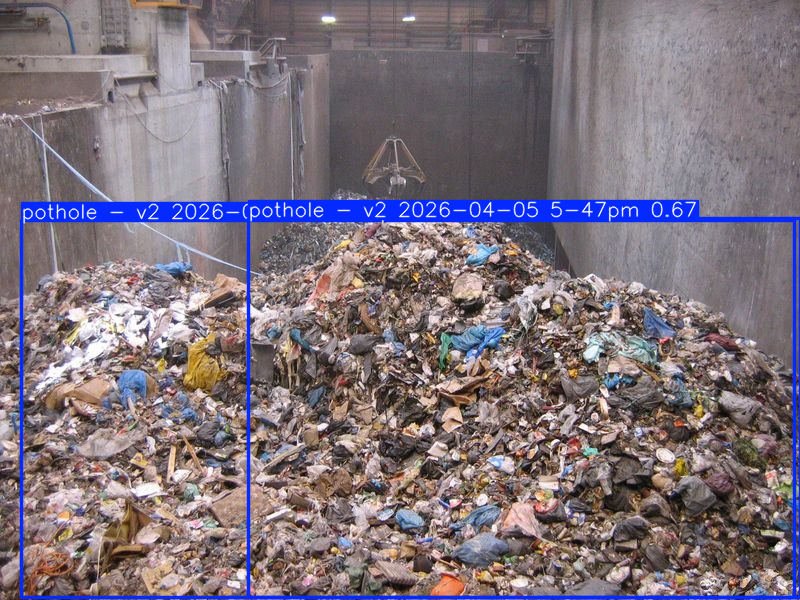

pothole - v2 2026-04-05 5-47pm 0.67
pothole - v2 2026-04-05 5-47pm 0.63


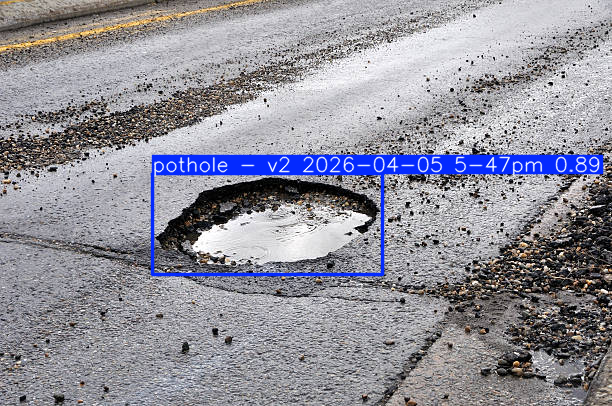

pothole - v2 2026-04-05 5-47pm 0.89


In [ ]:
from IPython.display import display
from PIL import Image

up = files.upload()
for fname in up:
    res = best.predict(source=fname, conf=0.4, verbose=False)[0]
    display(Image.fromarray(res.plot()[..., ::-1]))
    for c, p in zip(res.boxes.cls.tolist(), res.boxes.conf.tolist()):
        print(res.names[int(c)], round(p, 2))

## 8. Download the model

Save `best.pt` into your project's **`models`** folder (so the path is `models/best.pt`), install the AI extras,
and restart the server:

```
python -m pip install -r requirements-ai.txt
python -m uvicorn app.main:app --reload
```

Then open `http://127.0.0.1:8000/` and check that `ai_detection` shows `"ready": true`.

In [ ]:
files.download(best_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>